In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# ---------------------------------------
# 1. Configuration
# ---------------------------------------

ROSTER_DIR = Path("big12_rosters")
TOTALS_DIR = Path("big12_totals")
LOGO_DIR = Path("big12_logos")

NIL_FILE = "the-nil-standard-basketball-team-roster-spend-2026-11-02.csv"

TOP_N = 8

# ---------------------------------------
# 2. Load NIL data
# ---------------------------------------

nil_df = pd.read_csv(NIL_FILE)

big12_df = nil_df[
    nil_df["conference"] == "Big 12"
].copy()

big12_df = big12_df.sort_values(
    "est_roster_spend_usd",
    ascending=False
)

# ---------------------------------------
# 3. Helper functions
# ---------------------------------------

def height_to_inches(height):
    try:
        feet, inches = str(height).split("-")
        return int(feet) * 12 + int(inches)
    except (ValueError, TypeError):
        return np.nan


def normalize_name(name):
    return (
        str(name)
        .strip()
        .lower()
        .replace(".", "")
        .replace("'", "")
        .replace("’", "")
    )


# ---------------------------------------
# 4. Merge rosters and totals
# ---------------------------------------

all_players = []

for _, row in big12_df.iterrows():

    team = row["team"]
    spend = row["est_roster_spend_usd"]

    filename = f"{team.lower().replace(' ', '_')}.csv"

    roster_path = ROSTER_DIR / filename
    totals_path = TOTALS_DIR / filename

    if not roster_path.exists() or not totals_path.exists():
        print(f"Missing files for {team}")
        continue

    roster = pd.read_csv(roster_path)
    totals = pd.read_csv(totals_path)

    # Remove non-player rows
    totals = totals[
        totals["Player"].notna() &
        ~totals["Player"].isin(["Team Totals", "Player"])
    ].copy()

    # Normalize names for matching
    roster["player_key"] = roster["Player"].apply(normalize_name)
    totals["player_key"] = totals["Player"].apply(normalize_name)

    # Convert heights
    roster["height_inches"] = roster["Height"].apply(
        height_to_inches
    )

    # Merge, retaining all totals statistics
    merged = pd.merge(
        totals,
        roster[["player_key", "Height", "height_inches"]],
        on="player_key",
        how="left",
        validate="many_to_one"
    )

    # Convert statistics to numeric
    for col in ["G", "GS", "MP", "PTS", "TRB", "AST"]:
        merged[col] = pd.to_numeric(
            merged[col],
            errors="coerce"
        )

    # Calculate minutes per game
    merged["MPG"] = (
        merged["MP"] / merged["G"].replace(0, np.nan)
    )

    merged["team"] = team
    merged["nil_spend_usd"] = spend

    # Check unmatched player heights
    missing = merged[
        merged["height_inches"].isna()
    ]

    if not missing.empty:
        print(
            f"Missing heights for {team}: "
            f"{missing['Player'].tolist()}"
        )

    all_players.append(merged)

# Combine all players
big12_players_df = pd.concat(
    all_players,
    ignore_index=True
)

# ---------------------------------------
# 5. Select top 8 players by MPG
# ---------------------------------------

big12_top8_df = (
    big12_players_df[
        (big12_players_df["G"] > 0) &
        (big12_players_df["MPG"] > 0)
    ]
    .sort_values(
        ["team", "MPG", "MP", "GS"],
        ascending=[True, False, False, False]
    )
    .groupby("team")
    .head(TOP_N)
    .copy()
)

# Check that all selected players have heights
missing_top8 = big12_top8_df[
    big12_top8_df["height_inches"].isna()
]

if not missing_top8.empty:
    print("\nWARNING: Missing heights among top 8 players:")
    print(missing_top8[["team", "Player", "MPG"]])

# ---------------------------------------
# 6. Calculate team average heights
# ---------------------------------------

height_nil_df = (
    big12_top8_df
    .groupby("team")
    .agg(
        avg_height=("height_inches", "mean"),
        players_selected=("Player", "count"),
        heights_available=("height_inches", "count"),
        nil_spend_usd=("nil_spend_usd", "first")
    )
    .reset_index()
)

height_nil_df["nil_spend_millions"] = (
    height_nil_df["nil_spend_usd"] / 1_000_000
)

# Only plot teams with all 8 heights available
height_nil_df = height_nil_df[
    (height_nil_df["players_selected"] == TOP_N) &
    (height_nil_df["heights_available"] == TOP_N)
].copy()

print("\nTeam average heights:")
print(height_nil_df.to_string(index=False))

print("\nTeams ready for visualization:", len(height_nil_df))


Missing heights for Kansas: ['Leroy Blyden Jr.', 'Melvin Council Jr.', 'Dennis Parker Jr.']
Missing heights for Houston: ['Dedan Thomas Jr.', 'Corey Hadnot II', 'Arafan Diané']
Missing heights for Cincinnati: ['MJ Collins Jr.']
Missing heights for Baylor: ['Isaac Williams IV', 'Brett Decker Jr.', 'Andre Iguodala II']
Missing heights for Iowa State: ['Ryan Prather Jr.', 'Leon Bond III', 'Yusef Gray Jr.']
Missing heights for BYU: ['Robert Wright III', 'Bruce Branch III']
Missing heights for TCU: ['Miloš Šojić']

           team              Player        MPG
120         BYU   Robert Wright III  29.000000
123         BYU    Bruce Branch III  26.000000
95       Baylor    Brett Decker Jr.  25.500000
92       Baylor   Isaac Williams IV  24.000000
54   Cincinnati      MJ Collins Jr.  28.666667
38      Houston    Dedan Thomas Jr.  31.500000
43      Houston     Corey Hadnot II  21.000000
45      Houston        Arafan Diané  15.500000
108  Iowa State    Ryan Prather Jr.  28.500000
3        Kansa

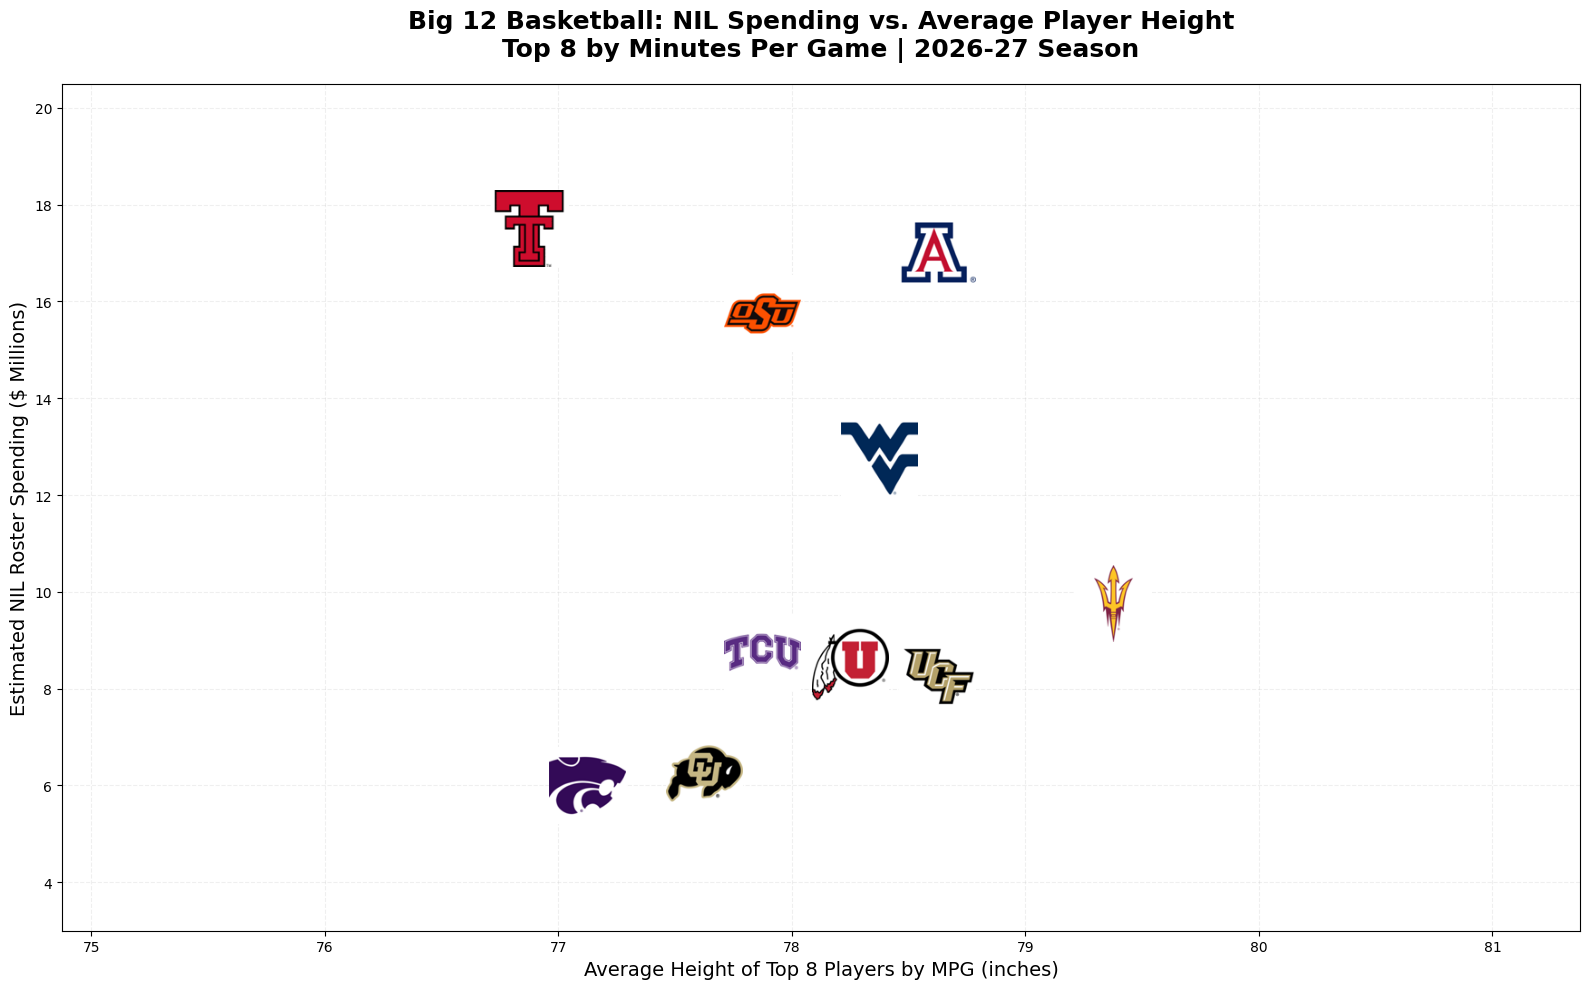

In [2]:

import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# ---------------------------------------
# 1. Set up chart
# ---------------------------------------

plot_df = height_nil_df.dropna(
    subset=["avg_height", "nil_spend_millions"]
).copy()

if plot_df.empty:
    raise ValueError("No valid teams available to plot.")

fig, ax = plt.subplots(figsize=(16, 10))

x_min = plot_df["avg_height"].min()
x_max = plot_df["avg_height"].max()

y_min = plot_df["nil_spend_millions"].min()
y_max = plot_df["nil_spend_millions"].max()

ax.set_xlim(x_min - 2, x_max + 2)
ax.set_ylim(y_min - 3, y_max + 3)

# Draw canvas for coordinate transformations
fig.canvas.draw()

placed_positions = []
MIN_DISTANCE = 65

# ---------------------------------------
# 2. Plot each team logo
# ---------------------------------------

for _, row in plot_df.iterrows():

    team = row["team"]
    x = row["avg_height"]
    y = row["nil_spend_millions"]

    filename = (
        LOGO_DIR /
        f"{team.lower().replace(' ', '_')}_logo.png"
    )

    # Mark the true data position
    ax.scatter(
        x, y,
        s=20,
        color="gray",
        alpha=0.6,
        zorder=3
    )

    if not filename.exists():
        print(f"Missing logo: {team}")
        ax.annotate(team, (x, y))
        continue

    logo = Image.open(filename).convert("RGBA")
    logo.thumbnail((85, 85))

    original_pos = ax.transData.transform((x, y))

    best_offset = (0, 0)
    found = False

    # Find a nearby location without overlap
    for radius in range(0, 201, 15):

        for angle in np.linspace(
            0, 2 * np.pi, 24, endpoint=False
        ):

            dx = radius * np.cos(angle)
            dy = radius * np.sin(angle)

            candidate = original_pos + np.array([dx, dy])

            if all(
                np.linalg.norm(candidate - previous) >= MIN_DISTANCE
                for previous in placed_positions
            ):
                best_offset = (dx, dy)
                placed_positions.append(candidate)
                found = True
                break

        if found:
            break

    if not found:
        placed_positions.append(
            original_pos + np.array(best_offset)
        )

    # Add logo
    imagebox = OffsetImage(
        np.asarray(logo),
        zoom=0.65
    )

    ab = AnnotationBbox(
        imagebox,
        (x, y),
        xybox=best_offset,
        xycoords="data",
        boxcoords="offset pixels",
        arrowprops=dict(
            arrowstyle="-",
            color="gray",
            alpha=0.5,
            linewidth=0.8
        ) if best_offset != (0, 0) else None,
        frameon=False,
        zorder=5
    )

    ax.add_artist(ab)

# ---------------------------------------
# 3. Formatting
# ---------------------------------------

ax.set_xlabel(
    "Average Height of Top 8 Players by MPG (inches)",
    fontsize=14
)

ax.set_ylabel(
    "Estimated NIL Roster Spending ($ Millions)",
    fontsize=14
)

ax.set_title(
    "Big 12 Basketball: NIL Spending vs. Average Player Height\n"
    "Top 8 by Minutes Per Game | 2026-27 Season",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.grid(alpha=0.2, linestyle="--")

plt.tight_layout()

plt.savefig(
    "big12_nil_vs_height_top8_mpg.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [5]:

import plotly.graph_objects as go
import pandas as pd
import numpy as np
import base64
from pathlib import Path

LOGO_DIR = Path("big12_logos")

# ---------------------------------------
# 1. Prepare data
# ---------------------------------------

plot_df = height_nil_df.dropna(
    subset=["avg_height", "nil_spend_millions"]
).copy()

# Convert average height from inches to feet/inches
def format_height(inches):
    # Round average height to nearest inch
    total_inches = int(round(inches))

    feet = total_inches // 12
    remaining_inches = total_inches % 12

    return f"{feet}'{remaining_inches}\""


plot_df["height_formatted"] = (
    plot_df["avg_height"].apply(format_height)
)

# ---------------------------------------
# 2. Convert logos to base64
# ---------------------------------------

def image_to_base64(path):
    with open(path, "rb") as image_file:
        encoded = base64.b64encode(
            image_file.read()
        ).decode("utf-8")

    return f"data:image/png;base64,{encoded}"


# ---------------------------------------
# 3. Create interactive chart
# ---------------------------------------

fig = go.Figure()

for _, row in plot_df.iterrows():

    team = row["team"]
    x = row["avg_height"]
    y = row["nil_spend_millions"]

    # Hover information
    hover_text = (
        f"<b>{team}</b><br>"
        f"Average Height: {row['height_formatted']}<br>"
        f"NIL Spending: ${y:.2f}M"
    )

    # Invisible marker for hover
    fig.add_trace(
        go.Scatter(
            x=[x],
            y=[y],
            mode="markers",
            marker=dict(
                size=65,
                color="rgba(0,0,0,0.01)"
            ),
            hovertext=hover_text,
            hoverinfo="text",
            showlegend=False
        )
    )

    # Load team logo
    filename = (
        LOGO_DIR /
        f"{team.lower().replace(' ', '_')}_logo.png"
    )

    if filename.exists():

        fig.add_layout_image(
            dict(
                source=image_to_base64(filename),
                xref="x",
                yref="y",
                x=x,
                y=y,
                sizex=0.95,
                sizey=1.5,
                xanchor="center",
                yanchor="middle",
                layer="above"
            )
        )

    else:
        print(f"Missing logo: {team}")

# ---------------------------------------
# 4. Format chart
# ---------------------------------------

fig.update_layout(
    title=dict(
        text=(
            "Big 12 Basketball: NIL Spending vs. Average Height"
            "<br><sup>Top 8 Players by MPG | 2026–27 Season</sup>"
        ),
        x=0.5
    ),

    xaxis_title="Average Height of Top 8 Players (inches)",
    yaxis_title="Estimated NIL Roster Spending ($ Millions)",

    template="plotly_white",

    width=1400,
    height=850,

    hovermode="closest",
    showlegend=False,

    margin=dict(l=90, r=90, t=110, b=90)
)

# Give logos extra space around edges
fig.update_xaxes(
    range=[
        plot_df["avg_height"].min() - 2,
        plot_df["avg_height"].max() + 2
    ],
    showgrid=True,
    gridcolor="rgba(0,0,0,0.08)"
)

fig.update_yaxes(
    range=[
        plot_df["nil_spend_millions"].min() - 3,
        plot_df["nil_spend_millions"].max() + 3
    ],
    showgrid=True,
    gridcolor="rgba(0,0,0,0.08)"
)

# ---------------------------------------
# 5. Display visualization
# ---------------------------------------

fig.show()

# ---------------------------------------
# 6. Export interactive HTML
# ---------------------------------------


fig.update_layout(
    title=dict(
        text=(
            "Big 12 Basketball: NIL Spending vs. Average Height"
            "<br><sup>Top 8 Players by MPG | 2026–27 Season</sup>"
        ),
        x=0.5
    ),

    xaxis_title="Average Height of Top 8 Players (inches)",
    yaxis_title="Estimated NIL Roster Spending ($ Millions)",

    template="plotly_white",

    # Allow chart to resize with its container
    autosize=True,

    # Remove fixed width and height
    margin=dict(l=75, r=40, t=100, b=75),

    hovermode="closest",
    dragmode=False,
    showlegend=False
)

# Keep axis ranges fixed
fig.update_xaxes(
    range=[
        plot_df["avg_height"].min() - 2,
        plot_df["avg_height"].max() + 2
    ],
    fixedrange=True
)

fig.update_yaxes(
    range=[
        plot_df["nil_spend_millions"].min() - 3,
        plot_df["nil_spend_millions"].max() + 3
    ],
    fixedrange=True
)

# Export interactive HTML
fig.write_html(
    "big12_nil_height_interactive.html",
    include_plotlyjs=True,
    full_html=True,
    config={
        "responsive": True,
        "scrollZoom": False,
        "displayModeBar": False,
        "doubleClick": False
    },
    default_width="100%",
    default_height="100%"
)


print("Saved: big12_nil_height_interactive.html")


Saved: big12_nil_height_interactive.html


Teams ready: 10


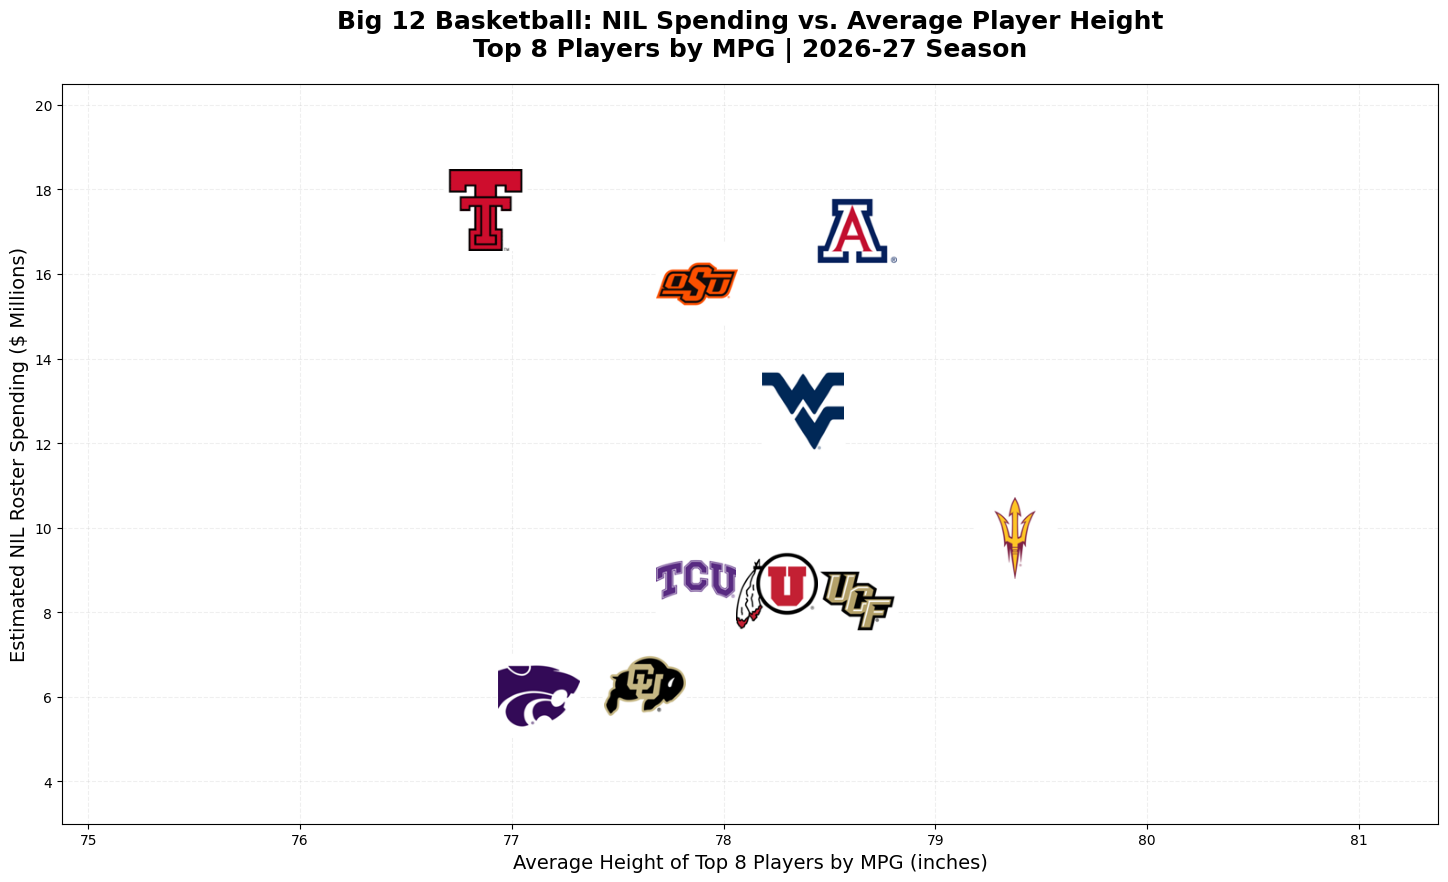

Saved visualization to: ../app/public/visualizations/nil/big12_nil_height.png


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# ---------------------------------------
# 1. Configuration
# ---------------------------------------

ROSTER_DIR = Path("big12_rosters")
TOTALS_DIR = Path("big12_totals")
LOGO_DIR = Path("big12_logos")

NIL_FILE = "the-nil-standard-basketball-team-roster-spend-2026-11-02.csv"

TOP_N = 8

# Save directly to React app
OUTPUT_DIR = Path("../app/public/visualizations/nil")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "big12_nil_height.png"

# ---------------------------------------
# 2. Load NIL data
# ---------------------------------------

nil_df = pd.read_csv(NIL_FILE)

big12_df = nil_df[
    nil_df["conference"] == "Big 12"
].copy()

big12_df = big12_df.sort_values(
    "est_roster_spend_usd",
    ascending=False
)

# ---------------------------------------
# 3. Helper functions
# ---------------------------------------

def height_to_inches(height):
    try:
        feet, inches = str(height).split("-")
        return int(feet) * 12 + int(inches)
    except (ValueError, TypeError):
        return np.nan


def normalize_name(name):
    return (
        str(name)
        .strip()
        .lower()
        .replace(".", "")
        .replace("'", "")
        .replace("’", "")
    )


# ---------------------------------------
# 4. Merge roster and totals data
# ---------------------------------------

all_players = []

for _, row in big12_df.iterrows():

    team = row["team"]
    spend = row["est_roster_spend_usd"]

    filename = f"{team.lower().replace(' ', '_')}.csv"

    roster_path = ROSTER_DIR / filename
    totals_path = TOTALS_DIR / filename

    if not roster_path.exists() or not totals_path.exists():
        print(f"Missing data for {team}")
        continue

    roster = pd.read_csv(roster_path)
    totals = pd.read_csv(totals_path)

    # Remove non-player rows
    totals = totals[
        totals["Player"].notna() &
        ~totals["Player"].isin(["Team Totals", "Player"])
    ].copy()

    # Normalize player names
    roster["player_key"] = roster["Player"].apply(normalize_name)
    totals["player_key"] = totals["Player"].apply(normalize_name)

    # Convert heights to inches
    roster["height_inches"] = roster["Height"].apply(
        height_to_inches
    )

    # Merge statistics with heights
    merged = pd.merge(
        totals,
        roster[["player_key", "height_inches"]],
        on="player_key",
        how="left",
        validate="many_to_one"
    )

    # Convert statistics to numeric
    for col in ["G", "GS", "MP"]:
        merged[col] = pd.to_numeric(
            merged[col],
            errors="coerce"
        )

    # Calculate minutes per game
    merged["MPG"] = (
        merged["MP"] /
        merged["G"].replace(0, np.nan)
    )

    merged["team"] = team
    merged["nil_spend_usd"] = spend

    all_players.append(merged)

big12_players_df = pd.concat(
    all_players,
    ignore_index=True
)

# ---------------------------------------
# 5. Select top 8 players by MPG
# ---------------------------------------

big12_top8_df = (
    big12_players_df[
        (big12_players_df["G"] > 0) &
        (big12_players_df["MPG"] > 0)
    ]
    .sort_values(
        ["team", "MPG", "MP", "GS"],
        ascending=[True, False, False, False]
    )
    .groupby("team")
    .head(TOP_N)
    .copy()
)

# ---------------------------------------
# 6. Calculate team average heights
# ---------------------------------------

height_nil_df = (
    big12_top8_df
    .groupby("team")
    .agg(
        avg_height=("height_inches", "mean"),
        players_selected=("Player", "count"),
        heights_available=("height_inches", "count"),
        nil_spend_usd=("nil_spend_usd", "first")
    )
    .reset_index()
)

height_nil_df["nil_spend_millions"] = (
    height_nil_df["nil_spend_usd"] / 1_000_000
)

# Only include teams with 8 valid heights
height_nil_df = height_nil_df[
    (height_nil_df["players_selected"] == TOP_N) &
    (height_nil_df["heights_available"] == TOP_N)
].copy()

print("Teams ready:", len(height_nil_df))

if height_nil_df.empty:
    raise ValueError("No valid team data available to plot.")

# ---------------------------------------
# 7. Create static visualization
# ---------------------------------------

fig, ax = plt.subplots(figsize=(16, 10))

x_min = height_nil_df["avg_height"].min()
x_max = height_nil_df["avg_height"].max()

y_min = height_nil_df["nil_spend_millions"].min()
y_max = height_nil_df["nil_spend_millions"].max()

ax.set_xlim(x_min - 2, x_max + 2)
ax.set_ylim(y_min - 3, y_max + 3)

# Leave room for labels and logos
fig.subplots_adjust(
    left=0.09,
    right=0.95,
    top=0.86,
    bottom=0.12
)

fig.canvas.draw()

placed_positions = []

# Minimum distance between logos (pixels)
MIN_DISTANCE = 75

# ---------------------------------------
# 8. Plot logos with overlap handling
# ---------------------------------------

for _, row in height_nil_df.iterrows():

    team = row["team"]
    x = row["avg_height"]
    y = row["nil_spend_millions"]

    filename = (
        LOGO_DIR /
        f"{team.lower().replace(' ', '_')}_logo.png"
    )

    # Mark true data position
    ax.scatter(
        x, y,
        s=25,
        color="gray",
        alpha=0.6,
        zorder=3
    )

    if not filename.exists():
        print(f"Missing logo: {team}")
        ax.annotate(
            team,
            (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )
        continue

    logo = Image.open(filename).convert("RGBA")
    logo.thumbnail((90, 90))

    original_pos = ax.transData.transform((x, y))

    best_offset = (0, 0)
    found = False

    # Find nearest position without overlapping
    for radius in range(0, 251, 15):

        for angle in np.linspace(
            0, 2 * np.pi, 32, endpoint=False
        ):

            dx = radius * np.cos(angle)
            dy = radius * np.sin(angle)

            candidate = original_pos + np.array([dx, dy])

            if all(
                np.linalg.norm(candidate - previous) >= MIN_DISTANCE
                for previous in placed_positions
            ):
                best_offset = (dx, dy)
                placed_positions.append(candidate)
                found = True
                break

        if found:
            break

    if not found:
        placed_positions.append(
            original_pos + np.array(best_offset)
        )

    # Add team logo
    imagebox = OffsetImage(
        np.asarray(logo),
        zoom=0.65
    )

    ab = AnnotationBbox(
        imagebox,
        (x, y),
        xybox=best_offset,
        xycoords="data",
        boxcoords="offset pixels",
        arrowprops=dict(
            arrowstyle="-",
            color="gray",
            alpha=0.5,
            linewidth=0.8
        ) if best_offset != (0, 0) else None,
        frameon=False,
        zorder=5
    )

    ax.add_artist(ab)

# ---------------------------------------
# 9. Format chart
# ---------------------------------------

ax.set_xlabel(
    "Average Height of Top 8 Players by MPG (inches)",
    fontsize=14
)

ax.set_ylabel(
    "Estimated NIL Roster Spending ($ Millions)",
    fontsize=14
)

ax.set_title(
    "Big 12 Basketball: NIL Spending vs. Average Player Height\n"
    "Top 8 Players by MPG | 2026-27 Season",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.grid(
    alpha=0.2,
    linestyle="--"
)

# ---------------------------------------
# 10. Export PNG
# ---------------------------------------

plt.savefig(
    OUTPUT_FILE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved visualization to: {OUTPUT_FILE}")
